<a href="https://colab.research.google.com/github/yusufyilmaz-data/turkiye-konut-deprem-haritasi/blob/main/turkiye_konut_deprem_haritasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install tcmb folium -q

import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import folium
import tcmb
from google.colab import userdata

istemci = tcmb.Client(
    api_key=userdata.get("EVDS_KEY"),
    base_url="https://evds3.tcmb.gov.tr/igmevdsms-dis/"
)
print("Hazır")

Hazır


In [2]:
kodlar = ["TR10","TR21","TR22","TR31","TR32","TR33","TR41","TR42","TR51",
          "TR52","TR61","TR62","TR63","TR71","TR72","TR81","TR82","TR83",
          "TR90","TRA1","TRA2","TRB1","TRB2","TRC1","TRC2","TRC3"]

konut = pd.DataFrame()
hatali = []
for kod in kodlar:
    try:
        konut[kod] = istemci.read(series=f"TP.KFE.{kod}",
                                  start_date="01-01-2010").iloc[:, 0]
    except Exception as e:
        hatali.append(kod)

print("Başarılı:", konut.shape[1], "bölge")
print("Hatalı:", hatali)
print(konut.tail(2).round(0))

Başarılı: 13 bölge
Hatalı: ['TR71', 'TR72', 'TR81', 'TR82', 'TR83', 'TR90', 'TRA1', 'TRA2', 'TRB1', 'TRB2', 'TRC1', 'TRC2', 'TRC3']
             TR10   TR21   TR22   TR31   TR32   TR33   TR41   TR42   TR51  \
Tarih                                                                       
2026-09-01  231.0  219.0  237.0  231.0  225.0  258.0  237.0  248.0  265.0   
2026-10-01  233.0  219.0  236.0  230.0  227.0  263.0  239.0  249.0  269.0   

             TR52   TR61   TR62   TR63  
Tarih                                   
2026-09-01  238.0  200.0  220.0  246.0  
2026-10-01  236.0  202.0  215.0  254.0  


In [3]:
try:
    istemci.read(series="TP.KFE.TR71", start_date="01-01-2010")
except Exception as e:
    print(type(e).__name__)
    print(str(e)[:400])

IndexError
list index out of range


In [4]:
for dg in istemci.datagroups:
    ad = (dg["DATAGROUP_NAME"] + " " + dg["DATAGROUP_NAME_ENG"]).lower()
    if "konut fiyat" in ad or "house price" in ad or "residential property price" in ad:
        print(dg["DATAGROUP_CODE"], "-", dg["DATAGROUP_NAME"])

bie_kfe - Konut Fiyat Endeksi
bie_yokfend - Yeni Olmayan Konutlar Fiyat Endeksi
bie_ykfe - Yeni Konutlar Fiyat Endeksi
bie_yokfe - Yeni Olmayan Konutlar Fiyat Endeksi (YOKFE) (2010=100) (Arşiv)
bie_tykfe - Yeni Konutlar Fiyat Endeksi (YKFE) (2010=100) (Arşiv)
bie_tkfe - Konut Fiyat Endeksi (KFE) (2010=100) (Arşiv)
bie_thedonikykfe - Yeni Konutlar Fiyat Endeksi (YKFE) (2017=100) (Arşiv)
bie_thedonikyokfe - Yeni Olmayan Konutlar Fiyat Endeksi (YOKFE) (2017=100) (Arşiv)
bie_hkfe - Konut Fiyat Endeksi (KFE) (2017=100) (Arşiv)


In [5]:
seriler = istemci.get_series_metadata(datagroup="bie_kfe")
for s in seriler:
    print(s["SERIE_CODE"], "-", s["SERIE_NAME"])

TP.KFE.TR - Konut Fiyat Endeksi (KFE)
TP.KFE.TR10 - TR10 (İstanbul)
TP.KFE.TR51 - TR51 (Ankara)
TP.KFE.TR31 - TR31 (İzmir)
TP.KFE.TR21 - TR21 (Edirne, Kırklareli, Tekirdağ)
TP.KFE.TR22 - TR22 (Balıkesir, Çanakkale)
TP.KFE.TR32 - TR32 (Aydın, Denizli, Muğla)
TP.KFE.TR33 - TR33 (Afyonkarahisar, Kütahya, Manisa, Uşak)
TP.KFE.TR41 - TR41 (Bursa, Eskişehir, Bilecik)
TP.KFE.TR42 - TR42 (Bolu, Kocaeli, Sakarya, Yalova, Düzce)
TP.KFE.TR52 - TR52 (Konya, Karaman)
TP.KFE.TR61 - TR61 (Antalya, Burdur, Isparta)
TP.KFE.TR62 - TR62 (Adana, Mersin)
TP.KFE.TR63 - TR63 (Hatay, Kahramanmaraş, Osmaniye)
TP.KFE.TR7 - TR7 (Nevşehir, Niğde, Kırıkkale, Kırşehir, Aksaray, Kayseri, Sivas, Yozgat)
TP.KFE.TR8 - TR8 (Zonguldak, Karabük, Bartın, Kastamonu, Çankırı, Sinop, Samsun, Tokat, Çorum, Amasya)
TP.KFE.TR9 - TR9 (Trabzon, Ordu, Giresun, Rize, Artvin, Gümüşhane)
TP.KFE.TRA - TRA (Erzurum, Erzincan, Bayburt, Ağrı, Kars, Iğdır, Ardahan)
TP.KFE.TRB - TRB (Malatya, Elazığ, Bingöl, Tunceli, Van, Muş, Bitlis, Hakka

In [6]:
kodlar = ["TR10","TR21","TR22","TR31","TR32","TR33","TR41","TR42","TR51",
          "TR52","TR61","TR62","TR63","TR7","TR8","TR9","TRA","TRB","TRC"]

konut = pd.DataFrame()
hatali = []
for kod in kodlar:
    try:
        konut[kod] = istemci.read(series=f"TP.KFE.{kod}",
                                  start_date="01-01-2010").iloc[:, 0]
    except Exception:
        hatali.append(kod)

print("Başarılı:", konut.shape[1], "bölge")
print("Hatalı:", hatali)
print(konut.tail(1).round(0).T)

Başarılı: 19 bölge
Hatalı: []
Tarih  2026-10-01
TR10        233.0
TR21        219.0
TR22        236.0
TR31        230.0
TR32        227.0
TR33        263.0
TR41        239.0
TR42        249.0
TR51        269.0
TR52        236.0
TR61        202.0
TR62        215.0
TR63        254.0
TR7         258.0
TR8         256.0
TR9         260.0
TRA         290.0
TRB         291.0
TRC         241.0


In [7]:
url = "https://raw.githubusercontent.com/alpers/Turkey-Maps-GeoJSON/master/tr-cities.json"
iller = gpd.read_file(url)

print(iller.shape)
print(iller.columns.tolist())
print(iller.drop(columns="geometry").head(10))

(81, 3)
['name', 'number', 'geometry']
       name  number
0     Adana       1
1  Adıyaman       2
2     Afyon       3
3      Ağrı       4
4   Aksaray      68
5    Amasya       5
6    Ankara       6
7   Antalya       7
8   Ardahan      75
9    Artvin       8


In [8]:
bolge_plakalari = {
    "TR10": [34],
    "TR21": [22, 39, 59],
    "TR22": [10, 17],
    "TR31": [35],
    "TR32": [9, 20, 48],
    "TR33": [3, 43, 45, 64],
    "TR41": [16, 26, 11],
    "TR42": [14, 41, 54, 77, 81],
    "TR51": [6],
    "TR52": [42, 70],
    "TR61": [7, 15, 32],
    "TR62": [1, 33],
    "TR63": [31, 46, 80],
    "TR7":  [50, 51, 71, 40, 68, 38, 58, 66],
    "TR8":  [67, 78, 74, 37, 18, 57, 55, 60, 19, 5],
    "TR9":  [61, 52, 28, 53, 8, 29],
    "TRA":  [25, 24, 69, 4, 36, 76, 75],
    "TRB":  [44, 23, 12, 62, 65, 49, 13, 30],
    "TRC":  [27, 2, 79, 63, 21, 47, 72, 73, 56],
}

plaka_bolge = {p: b for b, liste in bolge_plakalari.items() for p in liste}
iller["bolge"] = iller["number"].map(plaka_bolge)

print("Eşleşen il:", iller["bolge"].notna().sum(), "/ 81")
print(iller[iller["bolge"].isna()][["name", "number"]])

Eşleşen il: 81 / 81
Empty DataFrame
Columns: [name, number]
Index: []


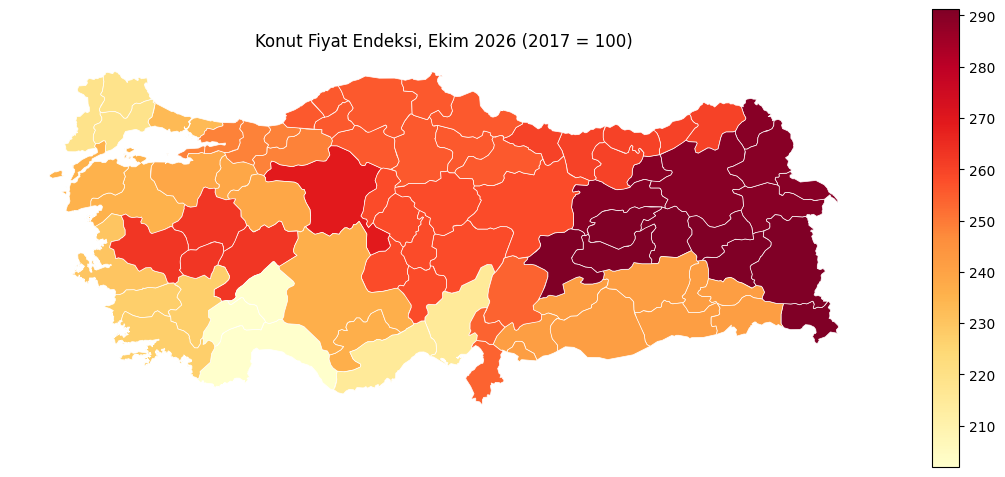

In [9]:
son = konut.iloc[-1]
iller["endeks"] = iller["bolge"].map(son)

iller.plot(column="endeks", cmap="YlOrRd", legend=True,
           figsize=(14, 7), edgecolor="white", linewidth=0.5)
plt.title("Konut Fiyat Endeksi, Ekim 2026 (2017 = 100)")
plt.axis("off")
plt.show()

Deprem sayısı: 900
                       time  latitude  longitude  mag  \
0  2026-11-24T15:39:43.392Z   37.0918    27.7790  4.7   
1  2026-11-21T21:25:54.969Z   38.7749    44.7563  4.5   
2  2026-11-09T12:28:18.768Z   37.4655    35.5760  4.7   
3  2026-10-04T11:43:22.802Z   37.7324    36.1316  5.1   
4  2026-10-04T11:36:26.472Z   37.7896    36.1679  4.7   

                                  place  
0      18 km ESE of Güvercinlik, Turkey  
1  26 km WSW of Qarah Ẕīā’ od Dīn, Iran  
2           18 km ESE of Aladağ, Turkey  
3             21 km ESE of Feke, Turkey  
4               22 km E of Feke, Turkey  


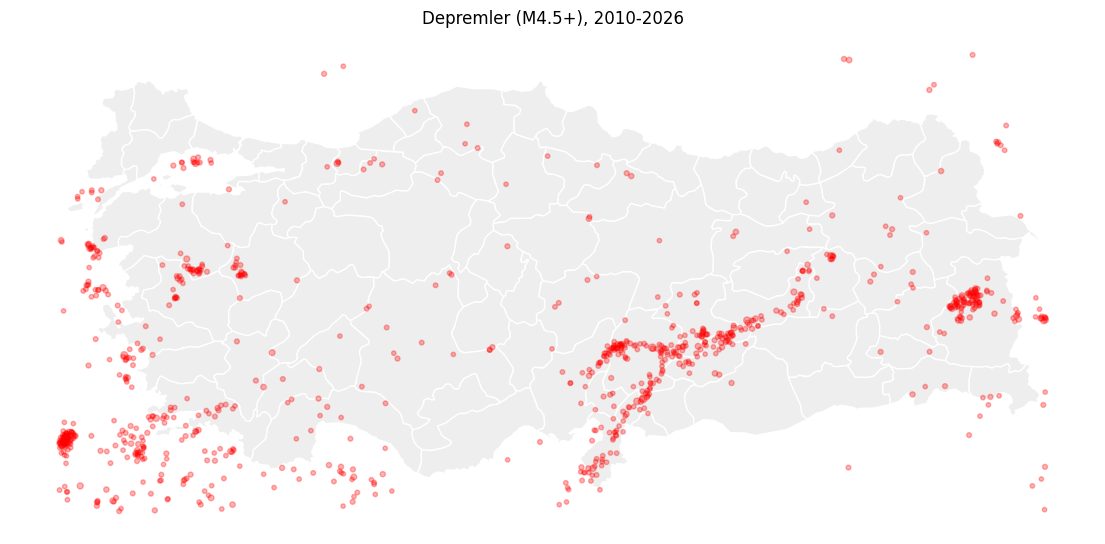

In [10]:
url = ("https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv"
       "&starttime=2010-01-01&endtime=2026-11-25&minmagnitude=4.5"
       "&minlatitude=35.5&maxlatitude=42.5&minlongitude=25.5&maxlongitude=45")
dep = pd.read_csv(url)

print("Deprem sayısı:", len(dep))
print(dep[["time", "latitude", "longitude", "mag", "place"]].head())

ax = iller.plot(color="#eeeeee", edgecolor="white", figsize=(14, 7))
ax.scatter(dep["longitude"], dep["latitude"],
           s=dep["mag"] ** 2 / 2, c="red", alpha=0.3)
plt.title("Depremler (M4.5+), 2010-2026")
plt.axis("off")
plt.show()

In [11]:
nokta = gpd.GeoDataFrame(
    dep, geometry=gpd.points_from_xy(dep["longitude"], dep["latitude"]),
    crs="EPSG:4326")
if iller.crs is None:
    iller = iller.set_crs("EPSG:4326")

icinde = gpd.sjoin(nokta, iller[["number", "name", "bolge", "geometry"]],
                   how="inner", predicate="within")

print("Türkiye karasındaki deprem:", len(icinde))

il_dep = (icinde.groupby("name")
          .agg(sayi=("mag", "count"), maks=("mag", "max"))
          .sort_values("sayi", ascending=False))
print(il_dep.head(10))

Türkiye karasındaki deprem: 550
               sayi  maks
name                     
Kahramanmaraş    89   7.8
Van              87   7.1
Malatya          55   6.0
Hatay            28   6.3
Adıyaman         28   5.6
Elazığ           25   6.7
Balıkesir        24   6.1
Adana            20   5.5
Kütahya          18   5.8
Muğla            18   5.8


In [12]:
bolge_dep = (icinde.groupby("bolge")
             .agg(deprem=("mag", "count"), maks=("mag", "max")))

oncesi = konut.loc["2023-01-01"]
sonrasi = konut.iloc[-1]
bolge_dep["fiyat_artis_yuzde"] = ((sonrasi / oncesi - 1) * 100).round(0)

print(bolge_dep.sort_values("deprem", ascending=False))

       deprem  maks  fiyat_artis_yuzde
bolge                                 
TRB       190   7.1              306.0
TR63      122   7.8              259.0
TRC        54   6.7              222.0
TR22       36   6.1              224.0
TR33       35   5.9              270.0
TR32       21   5.8              211.0
TR62       20   5.5              185.0
TR61       12   5.1              169.0
TRA        12   5.5              317.0
TR52       11   5.2              237.0
TR7        11   5.6              256.0
TR8        10   5.3              260.0
TR42        8   6.1              245.0
TR31        5   5.0              212.0
TR41        1   4.5              225.0
TR51        1   4.8              285.0
TR9         1   4.5              281.0


Korelasyon: 0.36


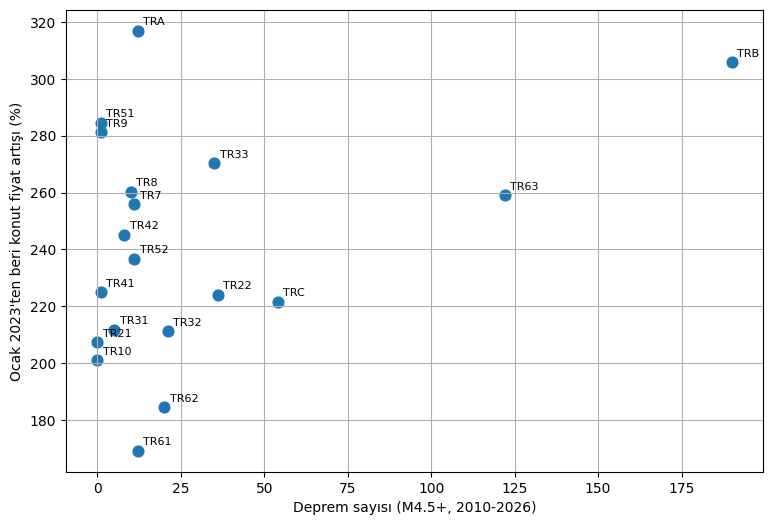

In [13]:
tum = pd.DataFrame(index=konut.columns)
tum["deprem"] = bolge_dep["deprem"]
tum["deprem"] = tum["deprem"].fillna(0)
tum["fiyat_artis"] = (sonrasi / oncesi - 1) * 100

print("Korelasyon:", round(tum["deprem"].corr(tum["fiyat_artis"]), 2))

ax = tum.plot.scatter(x="deprem", y="fiyat_artis", figsize=(9, 6), s=60)
for kod, satir in tum.iterrows():
    ax.annotate(kod, (satir["deprem"], satir["fiyat_artis"]),
                fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.xlabel("Deprem sayısı (M4.5+, 2010-2026)")
plt.ylabel("Ocak 2023'ten beri konut fiyat artışı (%)")
plt.grid(True)
plt.show()

In [16]:
m = folium.Map(location=[39, 35], zoom_start=6, tiles=None)

folium.Choropleth(
    geo_data=iller.to_json(), data=iller,
    columns=["name", "endeks"], key_on="feature.properties.name",
    fill_color="YlOrRd", fill_opacity=0.7, line_opacity=0.3,
    legend_name="Konut Fiyat Endeksi (2017 = 100)"
).add_to(m)

for _, r in icinde[icinde["mag"] >= 5.5].iterrows():
    folium.CircleMarker(
        [r["latitude"], r["longitude"]],
        radius=(r["mag"] - 4) * 3, color="black", weight=1,
        fill=True, fill_color="blue", fill_opacity=0.5,
        tooltip=f"M{r['mag']} - {r['place']}"
    ).add_to(m)

m